In [1]:
# Question: Locate the dataset
from pathlib import Path
current_dir = Path.cwd()
# path.cwd() tells us where the notebooks python kernel is working

if current_dir.name == "notebooks":
    project_dir = current_dir.parent
else:
    project_dir = current_dir

data_path = project_dir / "data" / "raw" / "Sample - Superstore.csv"

print("Current working directory:", current_dir)
print("\n\nProject directory:", project_dir)
print("\n\nDataset path:", data_path)
print("\n\nDataset found:", data_path.is_file())

Current working directory: C:\code play ground\Data-Science\Data-Science-Summer-Training-Projects\08-Major-project\04-RetailPulse_Analytics\RetailPulse_Project\notebooks


Project directory: C:\code play ground\Data-Science\Data-Science-Summer-Training-Projects\08-Major-project\04-RetailPulse_Analytics\RetailPulse_Project


Dataset path: C:\code play ground\Data-Science\Data-Science-Summer-Training-Projects\08-Major-project\04-RetailPulse_Analytics\RetailPulse_Project\data\raw\Sample - Superstore.csv


Dataset found: True


In [2]:
# Question: Load the dataset
import pandas as pd
df = pd.read_csv(data_path, encoding="cp1252")
# we used cp 1252 for encoding because the file is using windows-1252
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [3]:
# Question: inspect the dataset
print("DATASET DIMENSIONS")
print("-" *30)

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\n COLUMN NAMES")
print("-" * 30)

#this loop numbers the columns starting from 1
for number , column in enumerate(df.columns, start = 1):
    print(f"{number}. {column}")

print("\nDATASET INFORMATION")
print("-" *30)

df.info()

DATASET DIMENSIONS
------------------------------
Number of rows: 9994
Number of columns: 21

 COLUMN NAMES
------------------------------
1. Row ID
2. Order ID
3. Order Date
4. Ship Date
5. Ship Mode
6. Customer ID
7. Customer Name
8. Segment
9. Country
10. City
11. State
12. Postal Code
13. Region
14. Product ID
15. Category
16. Sub-Category
17. Product Name
18. Sales
19. Quantity
20. Discount
21. Profit

DATASET INFORMATION
------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null  

In [4]:
# Question : check data quality
# 1. Check missing values
print("MISSING VALUES")
print("-" * 30)

missing_values = df.isna().sum()
print(missing_values[missing_values > 0])

# 2. Check completely duplicated rows
print("\nDUPLICATE ROWS")
print("-" * 30)

duplicate_count = df.duplicated().sum()
print("Number of duplicate rows:", duplicate_count)

# 3. Check Row ID uniqueness
print("\nROW ID CHECK")
print("-" * 30)

print("Is Row ID unique?", df["Row ID"].is_unique)
# Check if every row is unique
print("Unique Row IDs:", df["Row ID"].nunique())
#nuique() counts number of unique values

MISSING VALUES
------------------------------
Series([], dtype: int64)

DUPLICATE ROWS
------------------------------
Number of duplicate rows: 0

ROW ID CHECK
------------------------------
Is Row ID unique? True
Unique Row IDs: 9994


In [5]:
# create the working copy and convert dates
df_clean = df.copy()
#df.copy creats a working copy of original dataset

df_clean["Order Date"] = pd.to_datetime(
    df_clean["Order Date"],
    format = "%m/%d/%Y"
)
df_clean["Ship Date"] = pd.to_datetime(
    df_clean["Ship Date"],
    format = "%m/%d/%Y"
)
print("Date conversion completed")

Date conversion completed


In [6]:
# this sell wil let you compare both original and copy
print("Original date types:")
print(df[["Order Date", "Ship Date"]].dtypes)

print("Converted date types:")
print(df_clean[["Order Date", "Ship Date"]].dtypes)

print("First five converted dates:")
display(df_clean[["Order Date", "Ship Date"]].head())

Original date types:
Order Date    object
Ship Date     object
dtype: object
Converted date types:
Order Date    datetime64[ns]
Ship Date     datetime64[ns]
dtype: object
First five converted dates:


,Order Date,Ship Date
0,2016-11-08,2016-11-11
1,2016-11-08,2016-11-11
2,2016-06-12,2016-06-16
3,2015-10-11,2015-10-18
4,2015-10-11,2015-10-18


In [7]:
# Extract information from dates
# Extract year from order date
df_clean["Order Year"] = df_clean["Order Date"].dt.year

# Extract month number from Order Date
df_clean["Order Month"] = df_clean["Order Date"].dt.month

# Extract month name from Order date
df_clean["Order Month Name"] = df_clean["Order Date"].dt.month_name()

# Calculate shipping duration in days
df_clean["Shipping Days"] = (
    df_clean["Ship Date"] - df_clean["Order Date"]
        ).dt.days

# Display the result
display(
    df_clean[
        [
            "Order Date",
            "Ship Date",
            "Order Year",
            "Order Month",
            "Order Month Name",
            "Shipping Days",
        ]
        ].head()
)

,Order Date,Ship Date,Order Year,Order Month,Order Month Name,Shipping Days
0,2016-11-08,2016-11-11,2016,11,November,3
1,2016-11-08,2016-11-11,2016,11,November,3
2,2016-06-12,2016-06-16,2016,6,June,4
3,2015-10-11,2015-10-18,2015,10,October,7
4,2015-10-11,2015-10-18,2015,10,October,7


In [8]:
# select the main numerical business columns 
business_columns = ["Sales", "Quantity", "Discount", "Profit"]

# calculate descriptive statistics
df_clean[business_columns].describe().round(2)
# .discribe() method calculates saveral useful statistics 

,Sales,Quantity,Discount,Profit
count,9994.00,9994.00,9994.00,9994.00
mean,229.86,3.79,0.16,28.66
std,623.25,2.23,0.21,234.26
min,0.44,1.00,0.00,-6599.98
25%,17.28,2.00,0.00,1.73
50%,54.49,3.00,0.20,8.67
75%,209.94,5.00,0.20,29.36
max,22638.48,14.00,0.80,8399.98


In [9]:
# Question : Compare product category
# Group the data by product category
category_summary = (
    #groupby splits the record into product categories
    # as index helps to produce clean table
    df_clean.groupby("Category", as_index=False)
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Units_Sold=("Quantity", "sum"),
        Line_Items=("Row ID", "count"),
        Average_Discount=("Discount", "mean"),
    )
)

# Calculate profit margin as a percentage of sales
category_summary["Profit_Margin_Pct"] = (
    category_summary["Total_Profit"]
    / category_summary["Total_Sales"]
    * 100
)

# Sort categories by total sales, highest first
category_summary = category_summary.sort_values(
    "Total_Sales",
    ascending=False
)

# Display the results
category_summary.round(2)

,Category,Total_Sales,Total_Profit,Units_Sold,Line_Items,Average_Discount,Profit_Margin_Pct
2,Technology,836154.03,145454.95,6939,1847,0.13,17.40
0,Furniture,741999.80,18451.27,8028,2121,0.17,2.49
1,Office Supplies,719047.03,122490.80,22906,6026,0.16,17.04


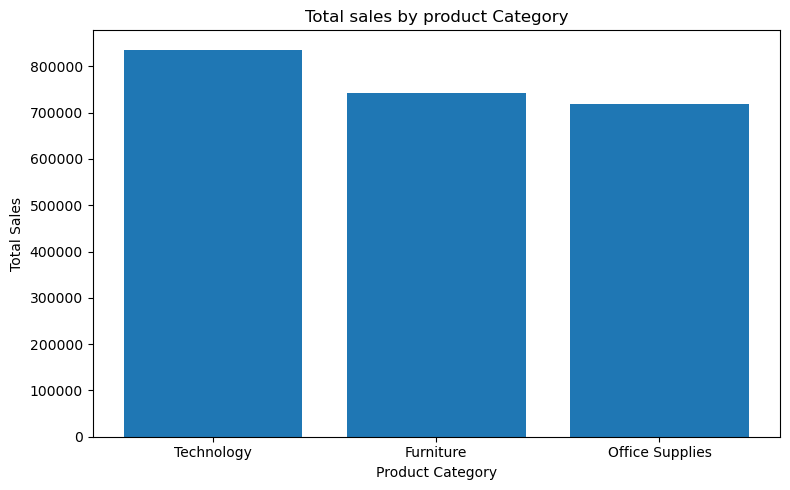

In [10]:
#Create visualization
import matplotlib.pyplot as plt

plt.figure(figsize = (8, 5))

# create a bar chart
plt.bar(
    category_summary["Category"],
    category_summary["Total_Sales"]
)

plt.title("Total sales by product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")

plt.tight_layout() #reduces overlaping chart elements

plt.show()

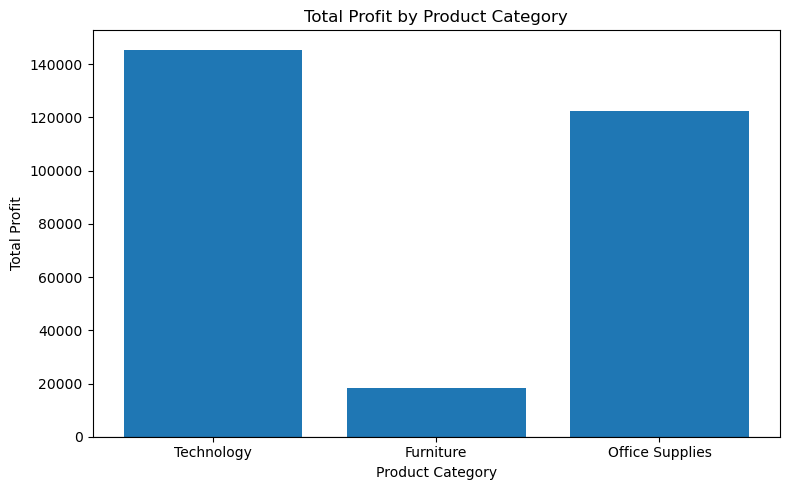

In [11]:
plt.figure(figsize = (8, 5))
plt.bar(
    category_summary["Category"],
    category_summary["Total_Profit"]
)
plt.title("Total Profit by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Profit")

plt.axhline(y = 0, color = "black", linewidth = 0.8) #adds a horizontal reference line at zero

plt.tight_layout()
plt.show()

In [12]:
# reviewed sales vs profit
# now find the least profitable sub categories
# Summarize sales and profit by product sub-category
subcategory_summary = (
    df_clean.groupby(
        ["Category", "Sub-Category"],
        as_index=False
    )
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Units_Sold=("Quantity", "sum"),
        Average_Discount=("Discount", "mean"),
        Line_Items=("Row ID", "count"),
    )
)

# Calculate profit margin as a percentage
subcategory_summary["Profit_Margin_Pct"] = (
    subcategory_summary["Total_Profit"]
    / subcategory_summary["Total_Sales"]
    * 100
)

# Show the least profitable sub-categories first
subcategory_summary = subcategory_summary.sort_values(
    "Total_Profit",
    ascending=True
)

display(subcategory_summary.round(2))

,Category,Sub-Category,Total_Sales,Total_Profit,Units_Sold,Average_Discount,Line_Items,Profit_Margin_Pct
3,Furniture,Tables,206965.53,-17725.48,1241,0.26,319,-8.56
0,Furniture,Bookcases,114880.00,-3472.56,868,0.21,228,-3.02
12,Office Supplies,Supplies,46673.54,-1189.10,647,0.08,190,-2.55
8,Office Supplies,Fasteners,3024.28,949.52,914,0.08,217,31.40
15,Technology,Machines,189238.63,3384.76,440,0.31,115,1.79
9,Office Supplies,Labels,12486.31,5546.25,1400,0.07,364,44.42
5,Office Supplies,Art,27118.79,6527.79,3000,0.07,796,24.07
7,Office Supplies,Envelopes,16476.40,6964.18,906,0.08,254,42.27
2,Furniture,Furnishings,91705.16,13059.14,3563,0.14,957,14.24
4,Office Supplies,Appliances,107532.16,18138.01,1729,0.17,466,16.87


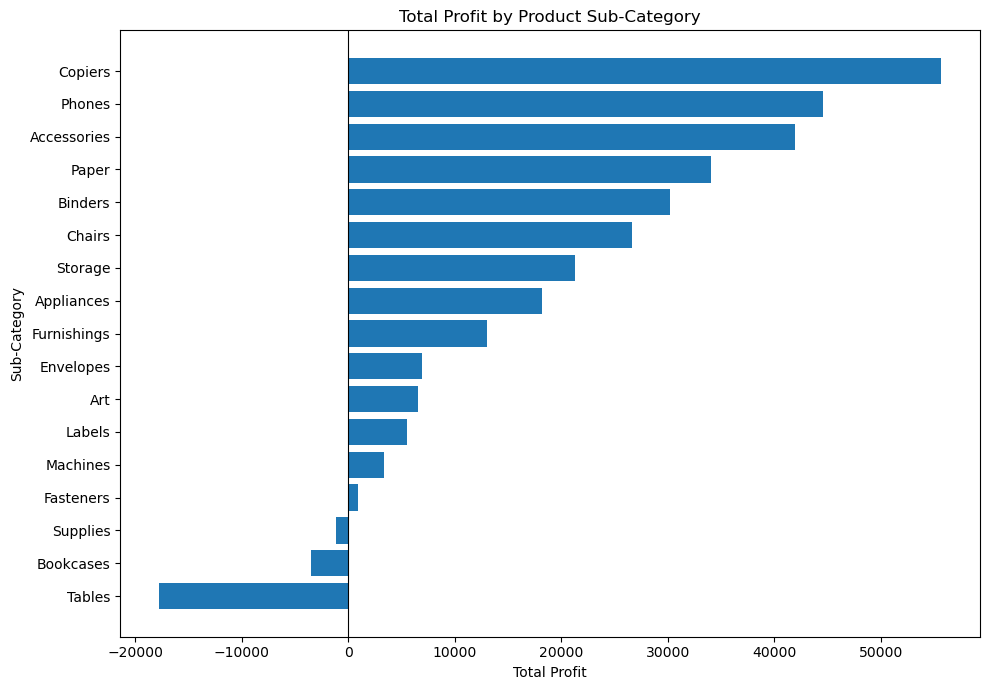

In [13]:
# Create a profit comparison chart
import matplotlib.pyplot as plt

# Sort from lowest profit to highest profit
profit_chart_data = subcategory_summary.sort_values(
    "Total_Profit",
    ascending=True
)
# Create the figure
plt.figure(figsize=(10, 7))

# Draw horizontal bars
plt.barh(
    profit_chart_data["Sub-Category"],
    profit_chart_data["Total_Profit"]
)

# Add a zero-profit reference line
plt.axvline(x=0, color="black", linewidth=0.8)

# Add labels and title
plt.title("Total Profit by Product Sub-Category")
plt.xlabel("Total Profit")
plt.ylabel("Sub-Category")

plt.tight_layout()
plt.show()

In [14]:
# Review what the chart tells us
# Investigate the relationship between discounts and profit
# Group transactions by discount level
discount_summary = (
    df_clean.groupby("Discount", as_index=False)
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Line_Items=("Row ID", "count"),
        Average_Profit_Per_Line=("Profit", "mean"),
    )
)

# Calculate profit margin for each discount level
discount_summary["Profit_Margin_Pct"] = (
    discount_summary["Total_Profit"]
    / discount_summary["Total_Sales"]
    * 100
)

# Display discount levels from lowest to highest
discount_summary = discount_summary.sort_values(
    "Discount",
    ascending=True
)

display(discount_summary.round(2))

,Discount,Total_Sales,Total_Profit,Line_Items,Average_Profit_Per_Line,Profit_Margin_Pct
0,0.00,1087908.47,320987.60,4798,66.90,29.51
1,0.10,54369.35,9029.18,94,96.06,16.61
2,0.15,27558.52,1418.99,52,27.29,5.15
3,0.20,764594.37,90337.31,3657,24.70,11.82
4,0.30,103226.66,-10369.28,227,-45.68,-10.05
5,0.32,14493.46,-2391.14,27,-88.56,-16.50
6,0.40,116417.78,-23057.05,206,-111.93,-19.81
7,0.45,5484.97,-2493.11,11,-226.65,-45.45
8,0.50,58918.54,-20506.43,66,-310.70,-34.80
9,0.60,6644.70,-5944.66,138,-43.08,-89.46


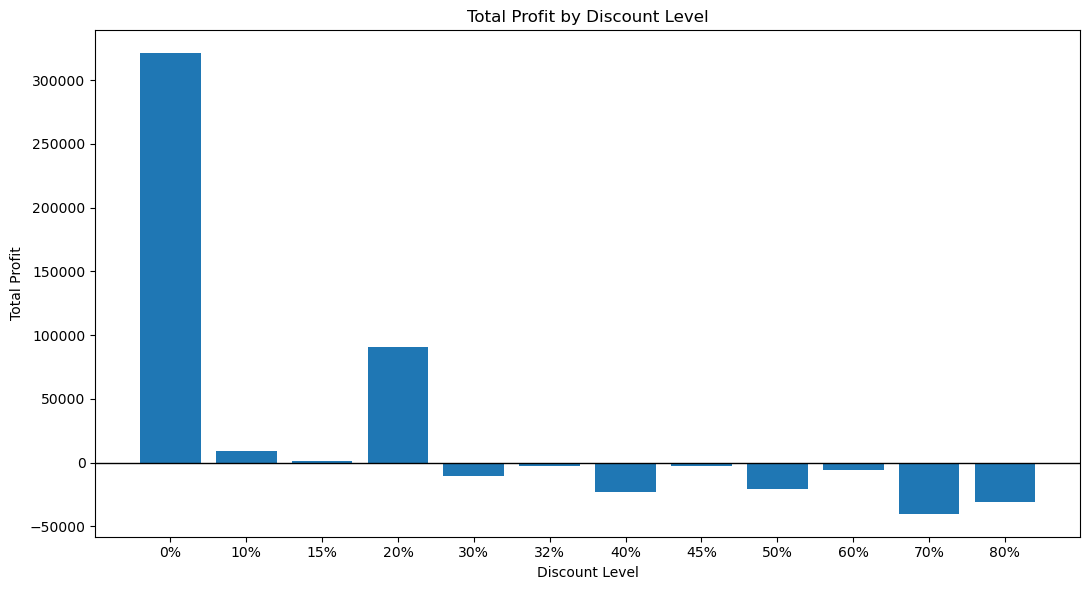

In [15]:
# Visualize profit by discount level
import matplotlib.pyplot as plt

# Convert discount values into readable percentage labels
discount_labels = (
    discount_summary["Discount"] * 100
).map(lambda value: f"{value:g}%")

# Create the chart
plt.figure(figsize=(11, 6))

plt.bar(
    discount_labels,
    discount_summary["Total_Profit"]
)

# Show the boundary between profit and loss
plt.axhline(y=0, color="black", linewidth=1)

plt.title("Total Profit by Discount Level")
plt.xlabel("Discount Level")
plt.ylabel("Total Profit")

plt.tight_layout()
plt.show()

In [16]:
# Filter loss making transactions
# Select the columns we want to investigate
loss_columns = [
    "Order ID",
    "Order Date",
    "Category",
    "Sub-Category",
    "Product Name",
    "Sales",
    "Discount",
    "Profit",
]

# Keep only rows where Profit is negative
loss_transactions = df_clean.loc[
    df_clean["Profit"] < 0,
    loss_columns
]

# Sort the biggest losses to the top
loss_transactions = loss_transactions.sort_values(
    "Profit",
    ascending=True
)

# Display the 10 largest transaction-line losses
display(loss_transactions.head(10))

,Order ID,Order Date,Category,Sub-Category,Product Name,Sales,Discount,Profit
7772,CA-2016-108196,2016-11-25,Technology,Machines,Cubify CubeX 3D Printer Double Head Print,4499.985,0.7,-6599.9780
683,US-2017-168116,2017-11-04,Technology,Machines,Cubify CubeX 3D Printer Triple Head Print,7999.980,0.5,-3839.9904
9774,CA-2014-169019,2014-07-26,Office Supplies,Binders,GBC DocuBind P400 Electric Binding System,2177.584,0.8,-3701.8928
3011,CA-2017-134845,2017-04-17,Technology,Machines,Lexmark MX611dhe Monochrome Laser Printer,2549.985,0.7,-3399.9800
4991,US-2017-122714,2017-12-07,Office Supplies,Binders,Ibico EPK-21 Electric Binding System,1889.990,0.8,-2929.4845
3151,CA-2015-147830,2015-12-15,Technology,Machines,Cubify CubeX 3D Printer Double Head Print,1799.994,0.7,-2639.9912
5310,CA-2017-131254,2017-11-19,Office Supplies,Binders,Fellowes PB500 Electric Punch Plastic Comb Bin...,1525.188,0.8,-2287.7820
9639,CA-2015-116638,2015-01-28,Furniture,Tables,Chromcraft Bull-Nose Wood Oval Conference Tabl...,4297.644,0.4,-1862.3124
1199,CA-2016-130946,2016-04-08,Office Supplies,Binders,GBC DocuBind P400 Electric Binding System,1088.792,0.8,-1850.9464
2697,CA-2014-145317,2014-03-18,Technology,Machines,Cisco TelePresence System EX90 Videoconferenci...,22638.480,0.5,-1811.0784


In [17]:
# Measure how many transactions lose money
total_lines = len(df_clean) #count the rows in our dataframe

loss_count = (df_clean["Profit"] < 0).sum()
profit_count = profit_count = (df_clean["Profit"] > 0).sum()
break_even_count = (df_clean["Profit"] == 0).sum()

print("TRANSACTION PROFITABILITY")
print("-" *35)

print("Total transaction lines:", total_lines)
print("Loss-making lines:", loss_count)
print("Profitable lines:", profit_count)
print("Break-even lines:", break_even_count)

print("\nPERCENTAGES")
print("-" * 35)

print(f"Loss-making: {loss_count / total_lines * 100:.2f}%")
print(f"Profitable: {profit_count / total_lines * 100:.2f}%")
print(f"Break-even: {break_even_count / total_lines * 100:.2f}%")

TRANSACTION PROFITABILITY
-----------------------------------
Total transaction lines: 9994
Loss-making lines: 1871
Profitable lines: 8058
Break-even lines: 65

PERCENTAGES
-----------------------------------
Loss-making: 18.72%
Profitable: 80.63%
Break-even: 0.65%


In [18]:
# Prepare profitability analysis
# Create temporary analysis columns without changing df_clean
df_analysis = df_clean.assign(
    Is_Loss=df_clean["Profit"] < 0,
    Loss_Amount=df_clean["Profit"].clip(upper=0).abs()
)

# Summarize profitability by category
category_profitability = (
    df_analysis.groupby("Category", as_index=False)
    .agg(
        Total_Lines=("Row ID", "count"),
        Net_Profit=("Profit", "sum"),
        Loss_Making_Lines=("Is_Loss", "sum"),
        Total_Loss_Amount=("Loss_Amount", "sum"),
    )
)

# Calculate the percentage of lines that make a loss
category_profitability["Loss_Line_Pct"] = (
    category_profitability["Loss_Making_Lines"]
    / category_profitability["Total_Lines"]
    * 100
)

# Sort categories by total loss amount
category_profitability = category_profitability.sort_values(
    "Total_Loss_Amount",
    ascending=False
)

display(category_profitability.round(2))

,Category,Total_Lines,Net_Profit,Loss_Making_Lines,Total_Loss_Amount,Loss_Line_Pct
0,Furniture,2121,18451.27,714,60936.11,33.66
1,Office Supplies,6026,122490.80,886,56615.26,14.70
2,Technology,1847,145454.95,271,38579.92,14.67


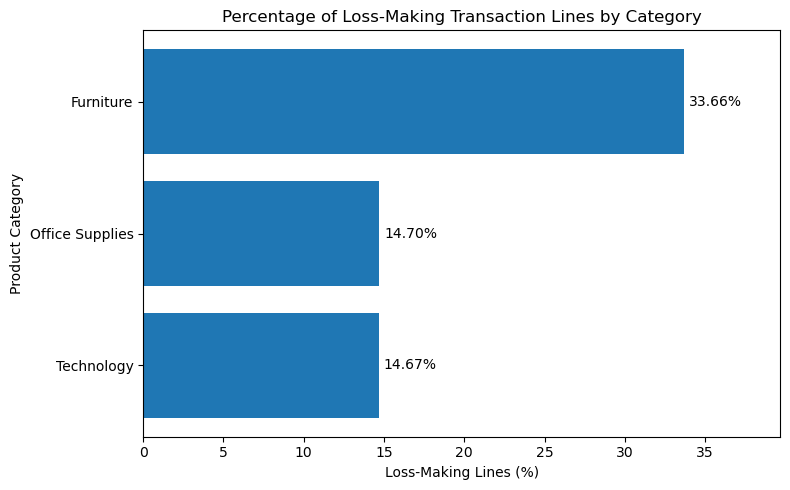

In [19]:
# Visualize the loss rate by category
# sort categories by their percentage of loss-making lines
import matplotlib.pyplot as plt

# Sort categories by their percentage of loss-making lines
loss_rate_chart = category_profitability.sort_values(
    "Loss_Line_Pct",
    ascending=True
)

plt.figure(figsize=(8, 5))

plt.barh(
    loss_rate_chart["Category"],
    loss_rate_chart["Loss_Line_Pct"]
)

plt.title("Percentage of Loss-Making Transaction Lines by Category")
plt.xlabel("Loss-Making Lines (%)")
plt.ylabel("Product Category")

# Display the percentage beside each bar
for position, value in enumerate(loss_rate_chart["Loss_Line_Pct"]):
    plt.text(value + 0.3, position, f"{value:.2f}%", va="center")


plt.xlim(0, loss_rate_chart["Loss_Line_Pct"].max() + 6)
plt.tight_layout()
plt.show()


In [20]:
# Create monthly summary
monthly_summary = (
    df_clean.groupby(
        pd.Grouper(key = "Order Date", freq = "MS")
    )
    .agg(
        Total_Sales = ("Sales", "sum"),
        Total_Profit = ("Profit", "sum"),
        Total_Orders = ("Order ID", "nunique"),
        Total_Line_Items = ("Row ID", "count"),
    )
    .reset_index()
)
# Display monthly summary
display(monthly_summary.head(12).round(2))

,Order Date,Total_Sales,Total_Profit,Total_Orders,Total_Line_Items
0,2014-01-01,14236.90,2450.19,32,79
1,2014-02-01,4519.89,862.31,28,46
2,2014-03-01,55691.01,498.73,71,157
3,2014-04-01,28295.34,3488.84,66,135
4,2014-05-01,23648.29,2738.71,69,122
5,2014-06-01,34595.13,4976.52,66,135
6,2014-07-01,33946.39,-841.48,65,143
7,2014-08-01,27909.47,5318.10,72,153
8,2014-09-01,81777.35,8328.10,130,268
9,2014-10-01,31453.39,3448.26,78,159


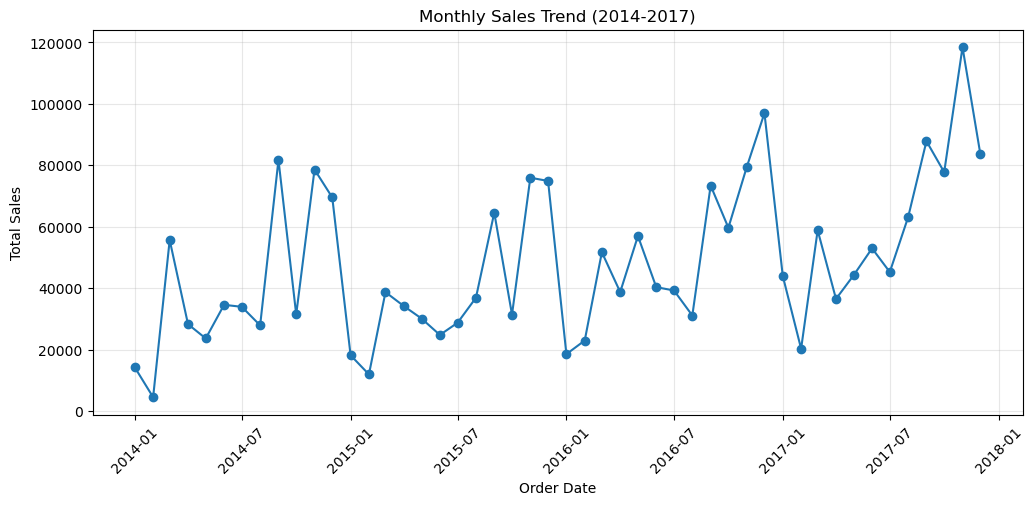

In [21]:
import matplotlib.pyplot as plt

#Create figure
plt.figure(figsize = (12, 5))

# Create monthly sales line chart
plt.plot(
    monthly_summary["Order Date"],
    monthly_summary["Total_Sales"],
    marker="o",
    linewidth=1.5
)

# plt.title and labels
plt.title("Monthly Sales Trend (2014-2017)")
plt.xlabel("Order Date")
plt.ylabel("Total Sales")

# Improve readability
plt.xticks(rotation = 45)
plt.grid(alpha = 0.3)



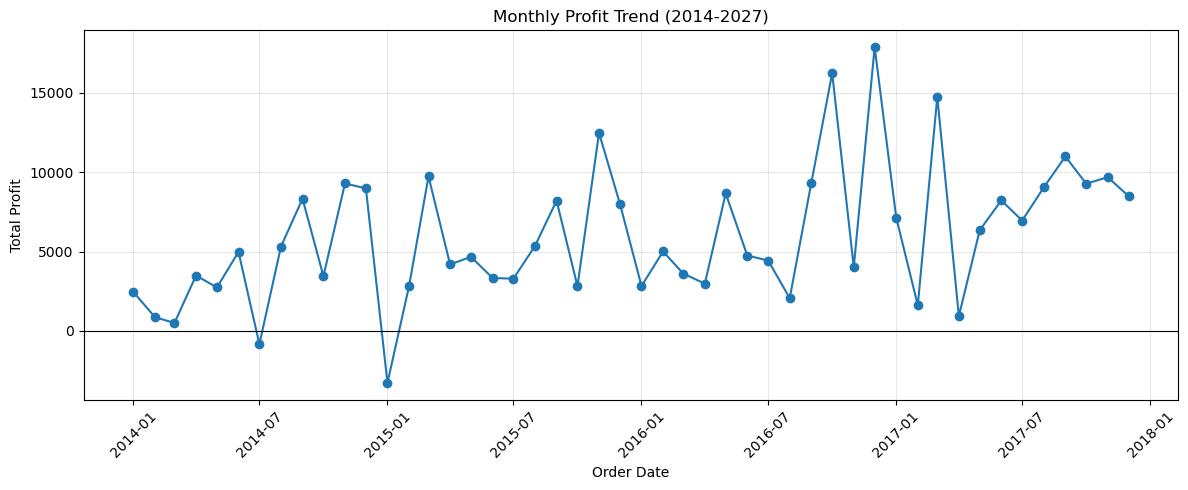

In [22]:
plt.figure(figsize=(12, 5))
plt.plot(
    monthly_summary["Order Date"],
    monthly_summary["Total_Profit"],
    marker="o",
    linewidth=1.5
)

plt.title("Monthly Profit Trend (2014-2027)")
plt.xlabel("Order Date")
plt.ylabel("Total Profit")

# Reference line at zero profit
plt.axhline(
    y=0,
    color="black",
    linewidth=0.8
)

plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [23]:
top_profit_months = monthly_summary.nlargest(
    5,
    "Total_Profit"
)

display(
    top_profit_months[
        ["Order Date", "Total_Sales", "Total_Profit"]
    ].round(2)
)

,Order Date,Total_Sales,Total_Profit
35,2016-12-01,96999.04,17885.31
33,2016-10-01,59687.74,16243.14
38,2017-03-01,58872.35,14751.89
22,2015-11-01,75972.56,12474.79
44,2017-09-01,87866.65,10991.56


In [24]:
worst_profit_months = monthly_summary.nsmallest(
    5,
    "Total_Profit"
)

display(
    worst_profit_months[
        ["Order Date", "Total_Sales", "Total_Profit"]
    ].round(2)
)

,Order Date,Total_Sales,Total_Profit
12,2015-01-01,18174.08,-3281.01
6,2014-07-01,33946.39,-841.48
2,2014-03-01,55691.01,498.73
1,2014-02-01,4519.89,862.31
39,2017-04-01,36521.54,933.29


In [25]:
# Create yearly summary
# Extract year from monthly dates
yearly_data = monthly_summary.assign(
    Order_Year=monthly_summary["Order Date"].dt.year
)

# Aggregate monthly data into yearly data
yearly_summary = (
    yearly_data.groupby("Order_Year", as_index=False)
    .agg(
        Total_Sales=("Total_Sales", "sum"),
        Total_Profit=("Total_Profit", "sum")
    )
)

# Calculate Year-over-Year growth percentages
yearly_summary["Sales_YoY_Growth_Pct"] = (
    yearly_summary["Total_Sales"].pct_change() * 100
)

yearly_summary["Profit_YoY_Growth_Pct"] = (
    yearly_summary["Total_Profit"].pct_change() * 100
)

# Display yearly performance
display(yearly_summary.round(2))


,Order_Year,Total_Sales,Total_Profit,Sales_YoY_Growth_Pct,Profit_YoY_Growth_Pct
0,2014,484247.50,49543.97,NaN,NaN
1,2015,470532.51,61618.60,-2.83,24.37
2,2016,609205.60,81795.17,29.47,32.74
3,2017,733215.26,93439.27,20.36,14.24


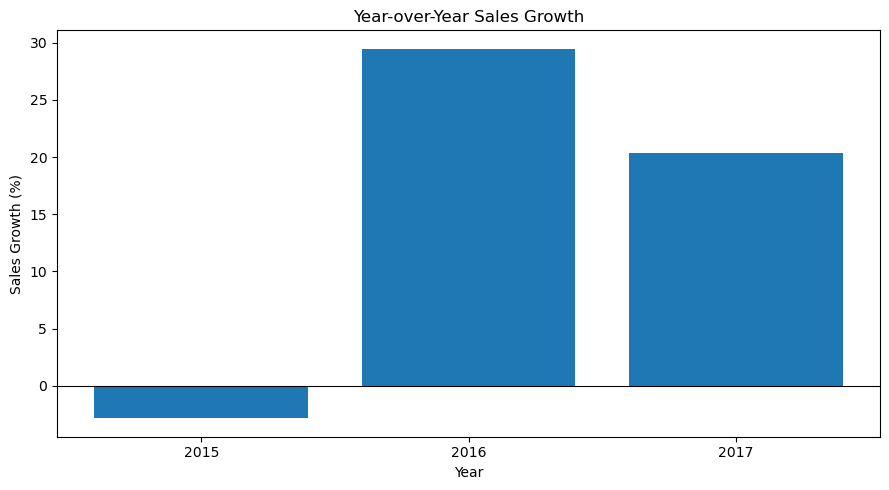

In [26]:
# visualize

sales_growth_data = yearly_summary.dropna(
    subset=["Sales_YoY_Growth_Pct"]
)

plt.figure(figsize=(9, 5))

plt.bar(
    sales_growth_data["Order_Year"].astype(str),
    sales_growth_data["Sales_YoY_Growth_Pct"]
)

plt.axhline(y=0, color="black", linewidth=0.8)

plt.title("Year-over-Year Sales Growth")
plt.xlabel("Year")
plt.ylabel("Sales Growth (%)")

plt.tight_layout()
plt.show()

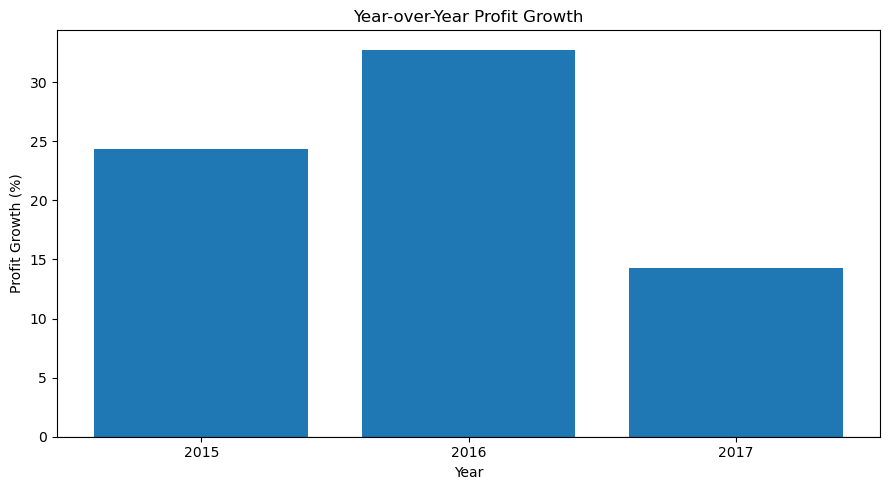

In [27]:
profit_growth_data = yearly_summary.dropna(
    subset=["Profit_YoY_Growth_Pct"]
)

plt.figure(figsize=(9, 5))

plt.bar(
    profit_growth_data["Order_Year"].astype(str),
    profit_growth_data["Profit_YoY_Growth_Pct"]
)

plt.axhline(y=0, color="black", linewidth=0.8)

plt.title("Year-over-Year Profit Growth")
plt.xlabel("Year")
plt.ylabel("Profit Growth (%)")

plt.tight_layout()
plt.show()